In [ ]:
import pandas as pd
import re
import string

print("Environment ready.")

Environment ready.


In [ ]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [ ]:
import pandas as pd

data = [

("I was charged twice for the same purchase.", "Billing", "Negative"),
("I don't recognize this charge on my account.", "Billing", "Negative"),
("Why was I charged an extra fee?", "Billing", "Negative"),
("My payment was declined but money was taken from my account.", "Billing", "Negative"),
("I was charged the wrong amount for my order.", "Billing", "Negative"),
("There is an unexpected charge on my bill.", "Billing", "Negative"),
("I think I was billed twice for my subscription.", "Billing", "Negative"),
("My invoice shows an amount that I did not expect.", "Billing", "Negative"),
("My card was charged but I did not receive confirmation.", "Billing", "Negative"),
("The amount on my bill is incorrect.", "Billing", "Negative"),

("Can you explain this charge on my statement?", "Billing", "Neutral"),
("Why does my invoice show a different amount?", "Billing", "Neutral"),
("I would like to understand my latest bill.", "Billing", "Neutral"),
("Can you check whether my payment went through?", "Billing", "Neutral"),
("My payment is still showing as pending.", "Billing", "Neutral"),
("Where can I find my billing details?", "Billing", "Neutral"),
("When will my payment appear on my account?", "Billing", "Neutral"),
("Can you explain how the billing process works?", "Billing", "Neutral"),
("How can I view my payment history?", "Billing", "Neutral"),
("How can I update my billing information?", "Billing", "Neutral"),

("My billing issue was solved quickly.", "Billing", "Positive"),
("Thank you for correcting the billing mistake.", "Billing", "Positive"),
("I appreciate the quick response about my payment.", "Billing", "Positive"),
("The billing information was clear and helpful.", "Billing", "Positive"),
("My payment was processed successfully.", "Billing", "Positive"),
("The refund appeared correctly on my statement.", "Billing", "Positive"),
("Thank you for explaining the charge.", "Billing", "Positive"),
("Everything looks correct on my latest invoice.", "Billing", "Positive"),
("I am satisfied with how the billing issue was handled.", "Billing", "Positive"),
("Your billing support was very helpful.", "Billing", "Positive"),


("The application keeps crashing when I try to open it.", "Technical", "Negative"),
("The website is not loading properly.", "Technical", "Negative"),
("I cannot log into the application because of an error.", "Technical", "Negative"),
("The app is very slow today.", "Technical", "Negative"),
("I am getting an error message when using the service.", "Technical", "Negative"),
("The application stopped working after the latest update.", "Technical", "Negative"),
("The website keeps freezing when I try to complete my order.", "Technical", "Negative"),
("I cannot upload my documents because of an error.", "Technical", "Negative"),
("The mobile application closes every time I open it.", "Technical", "Negative"),
("The login page is not responding.", "Technical", "Negative"),

("Can you help me understand this technical error?", "Technical", "Neutral"),
("Is there currently a problem with the application?", "Technical", "Neutral"),
("How can I update the application?", "Technical", "Neutral"),
("Where can I find the latest version of the app?", "Technical", "Neutral"),
("What should I do if the website does not load?", "Technical", "Neutral"),
("How can I troubleshoot the application?", "Technical", "Neutral"),
("Does the application require a specific browser?", "Technical", "Neutral"),
("Where can I report a technical problem?", "Technical", "Neutral"),
("How can I fix a login error?", "Technical", "Neutral"),
("Is there a system maintenance scheduled today?", "Technical", "Neutral"),

("The application is working perfectly now.", "Technical", "Positive"),
("Thank you, your technical support fixed the problem.", "Technical", "Positive"),
("Everything is working properly after the update.", "Technical", "Positive"),
("The website is much faster now.", "Technical", "Positive"),
("I appreciate the quick technical assistance.", "Technical", "Positive"),
("Your support team solved my technical problem.", "Technical", "Positive"),
("The application works smoothly now.", "Technical", "Positive"),
("Thank you for helping me fix the issue.", "Technical", "Positive"),
("The technical support was excellent.", "Technical", "Positive"),
("I am happy that the application is working again.", "Technical", "Positive"),


("I forgot my password and cannot access my account.", "Account", "Negative"),
("I cannot access my account anymore.", "Account", "Negative"),
("My account has been locked.", "Account", "Negative"),
("I forgot the email address associated with my account.", "Account", "Negative"),
("Someone may have accessed my account.", "Account", "Negative"),
("I cannot verify my account.", "Account", "Negative"),
("My account login is not working.", "Account", "Negative"),
("I think someone changed my account information.", "Account", "Negative"),
("I lost access to my account.", "Account", "Negative"),
("My account is blocked and I cannot sign in.", "Account", "Negative"),

("How can I change my email address?", "Account", "Neutral"),
("I want to update my personal information.", "Account", "Neutral"),
("How do I delete my account?", "Account", "Neutral"),
("How can I change my password?", "Account", "Neutral"),
("I need to update my phone number.", "Account", "Neutral"),
("How do I change my account details?", "Account", "Neutral"),
("Can I create a new account?", "Account", "Neutral"),
("Where can I manage my account settings?", "Account", "Neutral"),
("How does account verification work?", "Account", "Neutral"),
("Can I change the name on my account?", "Account", "Neutral"),

("Thank you, I was able to recover my account.", "Account", "Positive"),
("Your support helped me regain access to my account.", "Account", "Positive"),
("Changing my account information was very easy.", "Account", "Positive"),
("The account recovery process was simple.", "Account", "Positive"),
("I appreciate your help with my account.", "Account", "Positive"),
("My account is working perfectly now.", "Account", "Positive"),
("Thank you for helping me update my account.", "Account", "Positive"),
("The account verification was quick and easy.", "Account", "Positive"),
("I am happy with the account support.", "Account", "Positive"),
("Your team made the account recovery easy.", "Account", "Positive"),


("I need to cancel my order.", "Order", "Negative"),
("I want to change my order.", "Order", "Neutral"),
("Can I cancel an order after placing it?", "Order", "Neutral"),
("I ordered the wrong item and want to change it.", "Order", "Negative"),
("My order contains the wrong product.", "Order", "Negative"),
("I want to add an item to my order.", "Order", "Neutral"),
("Can I change the quantity of an item in my order?", "Order", "Neutral"),
("I accidentally placed the same order twice.", "Order", "Negative"),
("I need help correcting my order.", "Order", "Negative"),
("I want to cancel my purchase before it is shipped.", "Order", "Neutral"),

("How can I place an order?", "Order", "Neutral"),
("Can I modify my order after payment?", "Order", "Neutral"),
("Where can I see my order details?", "Order", "Neutral"),
("Can I add another product to an existing order?", "Order", "Neutral"),
("How do I change an item in my order?", "Order", "Neutral"),
("Can I cancel my order before delivery?", "Order", "Neutral"),
("How can I confirm my order?", "Order", "Neutral"),
("Can I change the quantity after placing an order?", "Order", "Neutral"),
("How do I know if my order was accepted?", "Order", "Neutral"),
("Can I reorder a product I bought before?", "Order", "Neutral"),

("My order was processed successfully.", "Order", "Positive"),
("Thank you for processing my order so quickly.", "Order", "Positive"),
("Everything in my order looks correct.", "Order", "Positive"),
("I am happy with my purchase.", "Order", "Positive"),
("The ordering process was very easy.", "Order", "Positive"),
("My order was confirmed without any problem.", "Order", "Positive"),
("Thank you for helping me change my order.", "Order", "Positive"),
("I am satisfied with how my order was handled.", "Order", "Positive"),
("The ordering process was simple and clear.", "Order", "Positive"),
("I had a great experience placing my order.", "Order", "Positive"),

("My order has not arrived yet.", "Delivery", "Negative"),
("My package is delayed.", "Delivery", "Negative"),
("I received the wrong item in my delivery.", "Delivery", "Negative"),
("The package arrived damaged.", "Delivery", "Negative"),
("My delivery is taking much longer than expected.", "Delivery", "Negative"),
("The package was supposed to arrive yesterday.", "Delivery", "Negative"),
("I have been waiting for my order for two weeks.", "Delivery", "Negative"),
("Nobody has contacted me about my delayed delivery.", "Delivery", "Negative"),
("My package has not moved for several days.", "Delivery", "Negative"),
("The delivery address seems to be incorrect.", "Delivery", "Negative"),

("Can you tell me where my order is?", "Delivery", "Neutral"),
("When should I expect my package to arrive?", "Delivery", "Neutral"),
("How can I track my delivery?", "Delivery", "Neutral"),
("Can you give me an estimated delivery date?", "Delivery", "Neutral"),
("Where is my package currently located?", "Delivery", "Neutral"),
("How long does delivery usually take?", "Delivery", "Neutral"),
("Can I change my delivery address?", "Delivery", "Neutral"),
("Does the package have a tracking number?", "Delivery", "Neutral"),
("When will my delivery be dispatched?", "Delivery", "Neutral"),
("How can I check the delivery status?", "Delivery", "Neutral"),

("My order arrived earlier than expected.", "Delivery", "Positive"),
("The delivery was very fast.", "Delivery", "Positive"),
("My package arrived safely and on time.", "Delivery", "Positive"),
("Thank you, my order arrived today.", "Delivery", "Positive"),
("I am very happy with the delivery service.", "Delivery", "Positive"),
("The delivery process was excellent.", "Delivery", "Positive"),
("My package arrived exactly when expected.", "Delivery", "Positive"),
("I am satisfied with the delivery service.", "Delivery", "Positive"),
("The package was delivered safely.", "Delivery", "Positive"),
("Thank you for the fast delivery.", "Delivery", "Positive"),

("I need a refund for a payment I made.", "Refund", "Negative"),
("I want my money back.", "Refund", "Negative"),
("I requested a refund but have not received it.", "Refund", "Negative"),
("My refund has not arrived yet.", "Refund", "Negative"),
("I was promised a refund but nothing has been returned.", "Refund", "Negative"),
("Why has my refund not been processed?", "Refund", "Negative"),
("I am still waiting for my refund.", "Refund", "Negative"),
("The refund amount I received is incorrect.", "Refund", "Negative"),
("I cancelled my order but have not received my money back.", "Refund", "Negative"),
("I have been waiting too long for my refund.", "Refund", "Negative"),

("How can I request a refund?", "Refund", "Neutral"),
("What is your refund policy?", "Refund", "Neutral"),
("How long does a refund take?", "Refund", "Neutral"),
("Can I get a refund for my order?", "Refund", "Neutral"),
("What are the conditions for receiving a refund?", "Refund", "Neutral"),
("Where can I request a refund?", "Refund", "Neutral"),
("How will I receive my refund?", "Refund", "Neutral"),
("Can I request a refund after cancelling my order?", "Refund", "Neutral"),
("What information is needed to request a refund?", "Refund", "Neutral"),
("How can I check the status of my refund?", "Refund", "Neutral"),

("Thank you, my refund was processed successfully.", "Refund", "Positive"),
("I received my refund today.", "Refund", "Positive"),
("The refund process was very quick.", "Refund", "Positive"),
("I appreciate the fast refund.", "Refund", "Positive"),
("Thank you for resolving my refund request.", "Refund", "Positive"),
("The refund was credited to my account correctly.", "Refund", "Positive"),
("I am satisfied with the refund process.", "Refund", "Positive"),
("Thank you for explaining the refund procedure.", "Refund", "Positive"),
("My refund was handled very efficiently.", "Refund", "Positive"),
("I appreciate your help with my refund.", "Refund", "Positive"),

("I would like to know more about your services.", "General", "Neutral"),
("What are your opening hours?", "General", "Neutral"),
("Where can I find more information about your company?", "General", "Neutral"),
("Do you offer customer support on weekends?", "General", "Neutral"),
("I have a general question about your service.", "General", "Neutral"),
("Where is your company located?", "General", "Neutral"),
("How can I learn more about your company?", "General", "Neutral"),
("What services do you currently offer?", "General", "Neutral"),
("Do you have a mobile application?", "General", "Neutral"),
("How can I contact your company?", "General", "Neutral"),

("What are your customer service hours?", "General", "Neutral"),
("Is your service available every day?", "General", "Neutral"),
("Can you tell me more about your company?", "General", "Neutral"),
("Where can I find your contact information?", "General", "Neutral"),
("How can I speak with someone from your team?", "General", "Neutral"),
("Where can I find information about your company?", "General", "Neutral"),
("Do you provide customer support?", "General", "Neutral"),
("What is the best way to contact your company?", "General", "Neutral"),
("Where are your services available?", "General", "Neutral"),
("Can you tell me about the services you provide?", "General", "Neutral"),

("Thank you for providing this information.", "General", "Positive"),
("Your website provides useful information.", "General", "Positive"),
("I appreciate the information you provided.", "General", "Positive"),
("The service information was very clear.", "General", "Positive"),
("Your customer service information is easy to find.", "General", "Positive"),
("Thank you for answering my question.", "General", "Positive"),
("I am satisfied with the information available.", "General", "Positive"),
("Your team was very helpful.", "General", "Positive"),
("Thank you for your helpful response.", "General", "Positive"),
("I appreciate the excellent customer service.", "General", "Positive"),
]

support_df = pd.DataFrame(
    data,
    columns=["ticket", "category", "sentiment"]
)
print("Dataset shape:", support_df.shape)
print("\nCategory distribution:")
print(support_df["category"].value_counts())
print("\nSentiment distribution:")
print(support_df["sentiment"].value_counts())
print("\nMissing values:")
print(support_df.isnull().sum())
print("\nDuplicate tickets:")
print(support_df["ticket"].duplicated().sum())
display(support_df.head(10))

Dataset shape: (210, 3)

Category distribution:
category
Billing      30
Technical    30
Account      30
Order        30
Delivery     30
Refund       30
General      30
Name: count, dtype: int64

Sentiment distribution:
sentiment
Neutral     85
Positive    70
Negative    55
Name: count, dtype: int64

Missing values:
ticket       0
category     0
sentiment    0
dtype: int64

Duplicate tickets:
0


,ticket,category,sentiment
0,I was charged twice for the same purchase.,Billing,Negative
1,I don't recognize this charge on my account.,Billing,Negative
2,Why was I charged an extra fee?,Billing,Negative
3,My payment was declined but money was taken fr...,Billing,Negative
4,I was charged the wrong amount for my order.,Billing,Negative
5,There is an unexpected charge on my bill.,Billing,Negative
6,I think I was billed twice for my subscription.,Billing,Negative
7,My invoice shows an amount that I did not expect.,Billing,Negative
8,My card was charged but I did not receive conf...,Billing,Negative
9,The amount on my bill is incorrect.,Billing,Negative


In [ ]:
import re
import string

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    text = re.sub(r"\s+", " ", text).strip()
    return text

support_df["clean_ticket"] = support_df["ticket"].apply(clean_text)

display(
    support_df[["ticket", "clean_ticket"]].head(10)
)

,ticket,clean_ticket
0,I was charged twice for the same purchase.,i was charged twice for the same purchase
1,I don't recognize this charge on my account.,i dont recognize this charge on my account
2,Why was I charged an extra fee?,why was i charged an extra fee
3,My payment was declined but money was taken fr...,my payment was declined but money was taken fr...
4,I was charged the wrong amount for my order.,i was charged the wrong amount for my order
5,There is an unexpected charge on my bill.,there is an unexpected charge on my bill
6,I think I was billed twice for my subscription.,i think i was billed twice for my subscription
7,My invoice shows an amount that I did not expect.,my invoice shows an amount that i did not expect
8,My card was charged but I did not receive conf...,my card was charged but i did not receive conf...
9,The amount on my bill is incorrect.,the amount on my bill is incorrect


In [ ]:
import re
import string
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)
    text = text.translate(
        str.maketrans("", "", string.punctuation)
    )
    text = re.sub(r"\s+", " ", text).strip()
    return text

support_df["clean_ticket"] = support_df["ticket"].apply(clean_text)
print("Original vs cleaned text:")
display(
    support_df[["ticket", "clean_ticket"]].head(10)
)

Original vs cleaned text:


,ticket,clean_ticket
0,I was charged twice for the same purchase.,i was charged twice for the same purchase
1,I don't recognize this charge on my account.,i dont recognize this charge on my account
2,Why was I charged an extra fee?,why was i charged an extra fee
3,My payment was declined but money was taken fr...,my payment was declined but money was taken fr...
4,I was charged the wrong amount for my order.,i was charged the wrong amount for my order
5,There is an unexpected charge on my bill.,there is an unexpected charge on my bill
6,I think I was billed twice for my subscription.,i think i was billed twice for my subscription
7,My invoice shows an amount that I did not expect.,my invoice shows an amount that i did not expect
8,My card was charged but I did not receive conf...,my card was charged but i did not receive conf...
9,The amount on my bill is incorrect.,the amount on my bill is incorrect


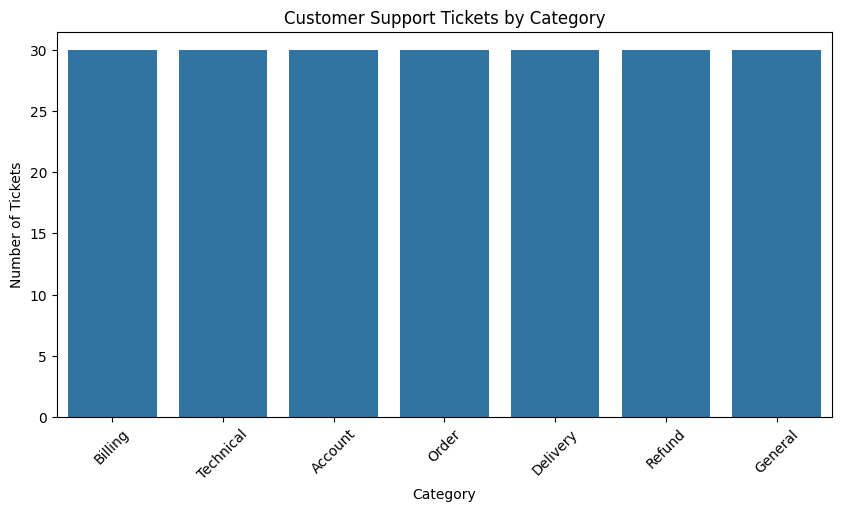

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.countplot(
    data=support_df,
    x="category",
    order=support_df["category"].value_counts().index
)

plt.title("Customer Support Tickets by Category")
plt.xlabel("Category")
plt.ylabel("Number of Tickets")
plt.xticks(rotation=45)
plt.show()

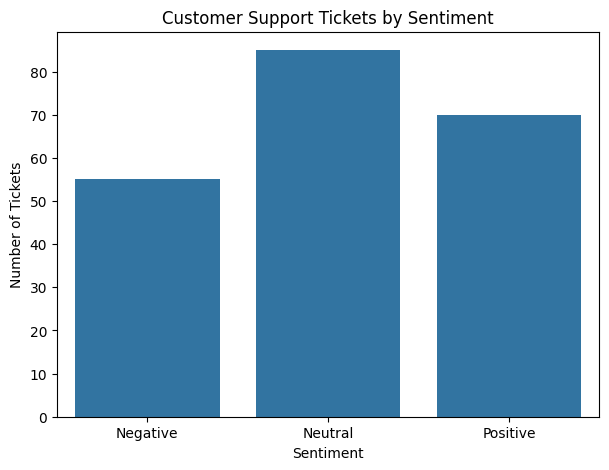

In [ ]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=support_df,
    x="sentiment",
    order=["Negative", "Neutral", "Positive"]
)

plt.title("Customer Support Tickets by Sentiment")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tickets")
plt.show()

Séparer les données

In [ ]:
from sklearn.model_selection import train_test_split

X = support_df["clean_ticket"]
y = support_df["category"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 168
Testing samples: 42


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

category_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=5000,
            stop_words="english"
        )
    ),
    (
        "classifier",
        LogisticRegression(max_iter=1000)
    )
])

category_model.fit(X_train, y_train)

print("Category classification model trained successfully.")

Category classification model trained successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

y_pred_category = category_model.predict(X_test)

category_accuracy = accuracy_score(
    y_test,
    y_pred_category
)

print(f"Category Model Accuracy: {category_accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred_category
    )
)

Category Model Accuracy: 88.10%

Classification Report:
              precision    recall  f1-score   support

     Account       1.00      0.83      0.91         6
     Billing       0.80      0.67      0.73         6
    Delivery       0.83      0.83      0.83         6
     General       1.00      1.00      1.00         6
       Order       0.86      1.00      0.92         6
      Refund       0.86      1.00      0.92         6
   Technical       0.83      0.83      0.83         6

    accuracy                           0.88        42
   macro avg       0.88      0.88      0.88        42
weighted avg       0.88      0.88      0.88        42



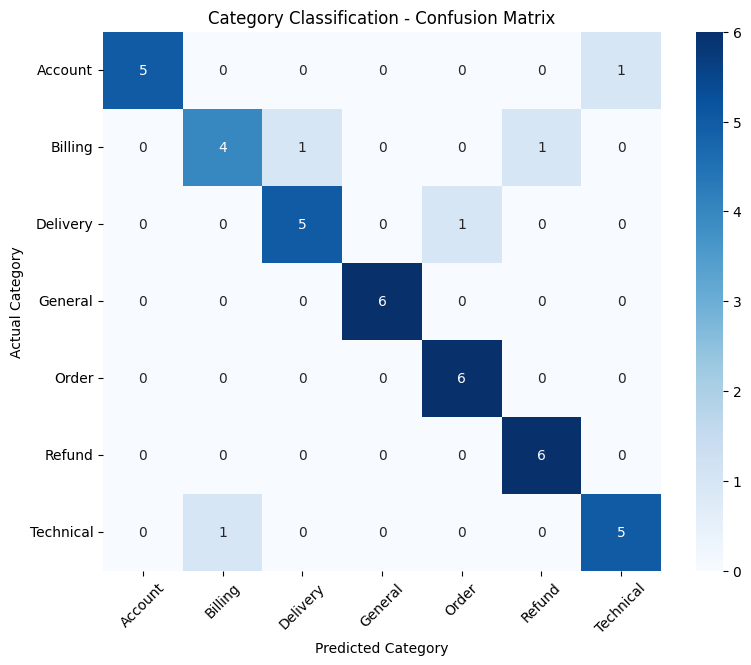

In [ ]:
from sklearn.metrics import confusion_matrix

cm_category = confusion_matrix(
    y_test,
    y_pred_category,
    labels=category_model.classes_
)

plt.figure(figsize=(9, 7))

sns.heatmap(
    cm_category,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=category_model.classes_,
    yticklabels=category_model.classes_
)

plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.title("Category Classification - Confusion Matrix")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.show()

In [ ]:
test_tickets = [
    "I need to cancel my order because I can no longer afford it.",
    "My package has not arrived yet.",
    "I was charged twice for the same purchase.",
    "I want to know how I can get a refund.",
    "I forgot my password and cannot access my account.",
    "The application keeps crashing when I try to open it.",
    "What are your opening hours?"
]

for ticket in test_tickets:
    prediction = category_model.predict([clean_text(ticket)])[0]
    probabilities = category_model.predict_proba(
        [clean_text(ticket)]
    )[0]

    confidence = probabilities.max()

    print("=" * 60)
    print("Ticket:", ticket)
    print("Predicted Category:", prediction)
    print(f"Confidence: {confidence:.2%}")

Ticket: I need to cancel my order because I can no longer afford it.
Predicted Category: Order
Confidence: 44.08%
Ticket: My package has not arrived yet.
Predicted Category: Delivery
Confidence: 58.81%
Ticket: I was charged twice for the same purchase.
Predicted Category: Billing
Confidence: 37.29%
Ticket: I want to know how I can get a refund.
Predicted Category: Refund
Confidence: 43.87%
Ticket: I forgot my password and cannot access my account.
Predicted Category: Account
Confidence: 55.13%
Ticket: The application keeps crashing when I try to open it.
Predicted Category: Technical
Confidence: 41.71%
Ticket: What are your opening hours?
Predicted Category: General
Confidence: 32.04%


sentiment analysis


In [ ]:
from sklearn.model_selection import train_test_split

X_sentiment = support_df["clean_ticket"]
y_sentiment = support_df["sentiment"]

X_train_sentiment, X_test_sentiment, y_train_sentiment, y_test_sentiment = train_test_split(
    X_sentiment,
    y_sentiment,
    test_size=0.20,
    random_state=42,
    stratify=y_sentiment
)

print("Training samples:", len(X_train_sentiment))
print("Testing samples:", len(X_test_sentiment))

Training samples: 168
Testing samples: 42


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

sentiment_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=5000,
            stop_words="english"
        )
    ),
    (
        "classifier",
        LogisticRegression(max_iter=1000)
    )
])

sentiment_model.fit(
    X_train_sentiment,
    y_train_sentiment
)

print("Sentiment classification model trained successfully.")

Sentiment classification model trained successfully.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    classification_report
)

y_pred_sentiment = sentiment_model.predict(
    X_test_sentiment
)

sentiment_accuracy = accuracy_score(
    y_test_sentiment,
    y_pred_sentiment
)

print(f"Sentiment Model Accuracy: {sentiment_accuracy:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_sentiment,
        y_pred_sentiment
    )
)

Sentiment Model Accuracy: 61.90%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.60      0.27      0.38        11
     Neutral       0.57      0.76      0.65        17
    Positive       0.71      0.71      0.71        14

    accuracy                           0.62        42
   macro avg       0.63      0.58      0.58        42
weighted avg       0.62      0.62      0.60        42



other

In [ ]:
sentiment_model_v2 = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            ngram_range=(1, 2),
            max_features=5000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            C=2.0
        )
    )
])

sentiment_model_v2.fit(
    X_train_sentiment,
    y_train_sentiment
)

y_pred_sentiment_v2 = sentiment_model_v2.predict(
    X_test_sentiment
)

sentiment_accuracy_v2 = accuracy_score(
    y_test_sentiment,
    y_pred_sentiment_v2
)

print(f"Sentiment Model V2 Accuracy: {sentiment_accuracy_v2:.2%}")

print("\nClassification Report:")
print(
    classification_report(
        y_test_sentiment,
        y_pred_sentiment_v2
    )
)

Sentiment Model V2 Accuracy: 88.10%

Classification Report:
              precision    recall  f1-score   support

    Negative       0.80      0.73      0.76        11
     Neutral       0.94      0.94      0.94        17
    Positive       0.87      0.93      0.90        14

    accuracy                           0.88        42
   macro avg       0.87      0.87      0.87        42
weighted avg       0.88      0.88      0.88        42



Sentiment confusion matrix

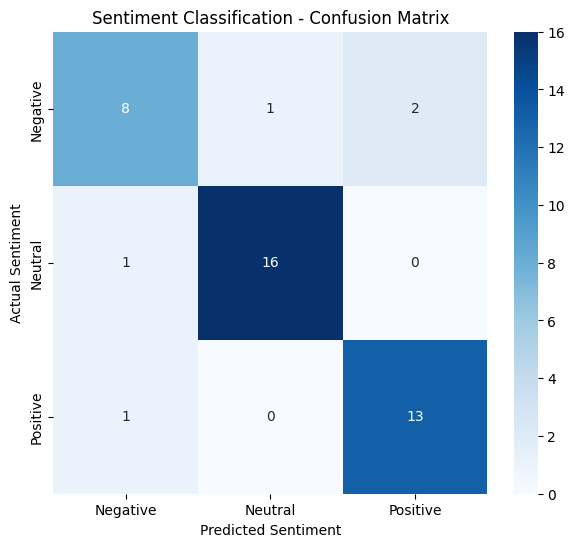

In [ ]:
from sklearn.metrics import confusion_matrix

cm_sentiment = confusion_matrix(
    y_test_sentiment,
    y_pred_sentiment_v2,
    labels=sentiment_model_v2.classes_
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_sentiment,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sentiment_model_v2.classes_,
    yticklabels=sentiment_model_v2.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Classification - Confusion Matrix")
plt.show()

build the final integrated analyzer

In [ ]:
def determine_priority(ticket, sentiment, category):
    ticket_lower = ticket.lower()
    urgent_keywords = [
        "fraud",
        "hacked",
        "stolen",
        "unauthorized",
        "emergency",
        "immediately",
        "urgent",
        "charged twice"
    ]
    high_keywords = [
        "angry",
        "extremely disappointed",
        "unacceptable",
        "terrible",
        "not working",
        "broken",
        "failed",
        "damaged",
        "late",
        "delayed",
        "two weeks",
        "weeks",
        "nobody has contacted",
        "no response",
        "still waiting"
    ]

    if any(word in ticket_lower for word in urgent_keywords):
        return "Urgent"

    if sentiment == "Negative":

        if any(word in ticket_lower for word in high_keywords):
            return "High"

        if category in [
            "Billing",
            "Delivery",
            "Technical",
            "Refund",
            "Account"
        ]:
            return "High"

    if sentiment in ["Neutral", "Positive"]:
        return "Low"

    return "Medium"

In [ ]:
def analyze_customer_ticket(ticket):
    cleaned_ticket = clean_text(ticket)
    category = category_model.predict(
        [cleaned_ticket]
    )[0]

    category_probabilities = category_model.predict_proba(
        [cleaned_ticket]
    )[0]

    category_confidence = category_probabilities.max()
    sentiment = sentiment_model_v2.predict(
        [cleaned_ticket]
    )[0]

    sentiment_probabilities = sentiment_model_v2.predict_proba(
        [cleaned_ticket]
    )[0]

    sentiment_confidence = sentiment_probabilities.max()
    priority = determine_priority(
        ticket,
        sentiment,
        category
    )

    return {
        "Ticket": ticket,
        "Category": category,
        "Category Confidence": f"{category_confidence:.2%}",
        "Sentiment": sentiment,
        "Sentiment Confidence": f"{sentiment_confidence:.2%}",
        "Priority": priority
    }

In [ ]:
for ticket in test_tickets:

    result = analyze_customer_ticket(ticket)

    print("=" * 70)
    print("Ticket:", result["Ticket"])
    print("Category:", result["Category"])
    print("Category Confidence:", result["Category Confidence"])
    print("Sentiment:", result["Sentiment"])
    print("Sentiment Confidence:", result["Sentiment Confidence"])
    print("Priority:", result["Priority"])

Ticket: I need to cancel my order because I can no longer afford it.
Category: Order
Category Confidence: 44.08%
Sentiment: Negative
Sentiment Confidence: 49.96%
Priority: Medium
Ticket: My package has not arrived yet.
Category: Delivery
Category Confidence: 58.81%
Sentiment: Negative
Sentiment Confidence: 76.24%
Priority: High
Ticket: I was charged twice for the same purchase.
Category: Billing
Category Confidence: 37.29%
Sentiment: Negative
Sentiment Confidence: 69.70%
Priority: Urgent
Ticket: I want to know how I can get a refund.
Category: Refund
Category Confidence: 43.87%
Sentiment: Neutral
Sentiment Confidence: 89.16%
Priority: Low
Ticket: I forgot my password and cannot access my account.
Category: Account
Category Confidence: 55.13%
Sentiment: Negative
Sentiment Confidence: 62.85%
Priority: High
Ticket: The application keeps crashing when I try to open it.
Category: Technical
Category Confidence: 41.71%
Sentiment: Negative
Sentiment Confidence: 41.72%
Priority: High
Ticket: Wh

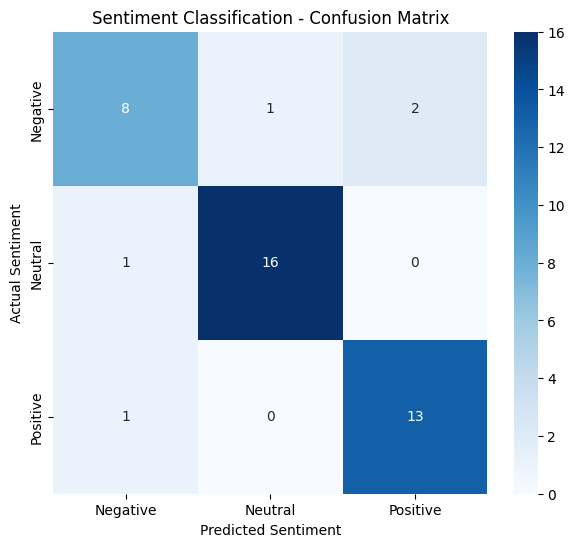

In [ ]:
cm_sentiment = confusion_matrix(
    y_test_sentiment,
    y_pred_sentiment_v2,
    labels=sentiment_model_v2.classes_
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm_sentiment,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=sentiment_model_v2.classes_,
    yticklabels=sentiment_model_v2.classes_
)

plt.xlabel("Predicted Sentiment")
plt.ylabel("Actual Sentiment")
plt.title("Sentiment Classification - Confusion Matrix")
plt.show()

In [ ]:
ticket = "Someone accessed my account and made an unauthorized payment."

result = analyze_customer_ticket(ticket)

print("CUSTOMER SUPPORT AI ANALYZER")
print("=" * 50)
print("Ticket:", result["Ticket"])
print("-" * 50)
print("Category:", result["Category"])
print("Category Confidence:", result["Category Confidence"])
print("Sentiment:", result["Sentiment"])
print("Sentiment Confidence:", result["Sentiment Confidence"])
print("Priority:", result["Priority"])

CUSTOMER SUPPORT AI ANALYZER
Ticket: Someone accessed my account and made an unauthorized payment.
--------------------------------------------------
Category: Account
Category Confidence: 38.40%
Sentiment: Negative
Sentiment Confidence: 58.21%
Priority: Urgent


an Analyze Ticket button,

In [ ]:
import ipywidgets as widgets
from IPython.display import display

ticket_input = widgets.Textarea(
    value="",
    placeholder="Enter a customer support ticket...",
    description="Ticket:",
    layout=widgets.Layout(width="700px", height="100px")
)

analyze_button = widgets.Button(
    description="Analyze Ticket",
    button_style="primary"
)

output = widgets.Output()

In [ ]:
def on_analyze_button_clicked(b):

    with output:
        output.clear_output()

        ticket = ticket_input.value.strip()

        if not ticket:
            print("Please enter a customer support ticket.")
            return

        result = analyze_customer_ticket(ticket)

        print("=" * 60)
        print("AI CUSTOMER SUPPORT ANALYZER")
        print("=" * 60)

        print(f"Ticket: {result['Ticket']}")
        print()

        print(f"Category: {result['Category']}")
        print(f"Category Confidence: {result['Category Confidence']}")
        print()

        print(f"Sentiment: {result['Sentiment']}")
        print(f"Sentiment Confidence: {result['Sentiment Confidence']}")
        print()

        print(f"Priority: {result['Priority']}")
        print("=" * 60)


analyze_button.on_click(on_analyze_button_clicked)

In [ ]:
display(
    ticket_input,
    analyze_button,
    output
)

Textarea(value='', description='Ticket:', layout=Layout(height='100px', width='700px'), placeholder='Enter a c…

Button(button_style='primary', description='Analyze Ticket', style=ButtonStyle())

Output()